Notebook cleans PG&E dataset to create a processed distribution grid geopackage 

## Set-Up

In [ ]:
#import packages
import pandas as pd
import geopandas as gpd
import networkx as nx
from pathlib import Path
import matplotlib.pyplot as plt

In [2]:
#set paths for sript, data, and scratch folder
script_fldr = Path.cwd() 
project_fldr = Path.cwd().parent
raw_data_fldr = project_fldr / 'Data' / 'Raw'
processed_data_fldr = project_fldr / 'Data' / 'Processed'

print(project_fldr)
print(script_fldr)
print(raw_data_fldr)
print(processed_data_fldr)

v:\GDA_Final_Project
v:\GDA_Final_Project\Scripts
v:\GDA_Final_Project\Data\Raw
v:\GDA_Final_Project\Data\Processed


## Data Cleaning 

### Data Import

In [4]:
#list of columns to import
line_columns_list = ['FeederId', 'CSV_LineSection','FeederName', 'voltage_kv', 'phase_cnt', 'Division', 'geometry', 'globalid']
ICA_NA_columns_list = ['feeder_id', 'numberofphases', 'globalid', 'division', 'geometry']

#import all three geopackages 
gdf_DRP_line = gpd.read_file(raw_data_fldr/'San_Jose_DRP_line.gpkg',
                             columns=line_columns_list)
gdf_LGP_line = gpd.read_file(raw_data_fldr/'San_Jose_LGP_line.gpkg',
                             columns=line_columns_list)
gdf_ICA_NA = gpd.read_file(raw_data_fldr/'San_Jose_ICA_NA.gpkg',
                           columns=ICA_NA_columns_list).rename(columns={'feeder_id':'FeederId', 
                                                                        'numberofphases':'phase_cnt', 
                                                                        'division':'Division'})
gdf_substations = gpd.read_file(raw_data_fldr/'San_Jose_dsubstations.gpkg').rename(columns={'Voltage_kV':'voltage_kv'})

### Combine DRP and LGP line data

In [6]:
#check coord system
gdf_DRP_line.crs

<Projected CRS: EPSG:26910>
Name: NAD83 / UTM zone 10N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: North America - between 126°W and 120°W - onshore and offshore. Canada - British Columbia; Northwest Territories; Yukon. United States (USA) - California; Oregon; Washington.
- bounds: (-126.0, 30.54, -119.99, 81.8)
Coordinate Operation:
- name: UTM zone 10N
- method: Transverse Mercator
Datum: North American Datum 1983
- Ellipsoid: GRS 1980
- Prime Meridian: Greenwich

In [7]:
#check coord system match
gdf_DRP_line.crs == gdf_LGP_line.crs == gdf_ICA_NA.crs

True

In [8]:
gdf_DRP_line.info()


<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 86088 entries, 0 to 86087
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   FeederId         86088 non-null  str     
 1   FeederName       86088 non-null  str     
 2   CSV_LineSection  54530 non-null  str     
 3   voltage_kv       86088 non-null  float64 
 4   phase_cnt        86042 non-null  float64 
 5   globalid         86088 non-null  str     
 6   Division         86088 non-null  str     
 7   geometry         86088 non-null  geometry
dtypes: float64(2), geometry(1), str(5)
memory usage: 11.1 MB


In [9]:
gdf_LGP_line.info() 

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 94020 entries, 0 to 94019
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype   
---  ------           --------------  -----   
 0   FeederId         94020 non-null  str     
 1   FeederName       94020 non-null  str     
 2   globalid         94020 non-null  str     
 3   CSV_LineSection  94020 non-null  str     
 4   voltage_kv       90948 non-null  float64 
 5   phase_cnt        93972 non-null  float64 
 6   Division         94020 non-null  str     
 7   geometry         94020 non-null  geometry
dtypes: float64(2), geometry(1), str(5)
memory usage: 12.4 MB


In [10]:
gdf_ICA_NA.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 29065 entries, 0 to 29064
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   FeederId   29065 non-null  str     
 1   phase_cnt  29065 non-null  int32   
 2   globalid   29065 non-null  str     
 3   Division   29065 non-null  str     
 4   geometry   29065 non-null  geometry
dtypes: geometry(1), int32(1), str(3)
memory usage: 2.5 MB


In [11]:
#create new columns indicating file source
gdf_DRP_line["source"], gdf_ICA_NA["source"], gdf_LGP_line["source"] = "drp_line", "drp_ica_na", "lgp_line"

In [12]:
#there are ~30 feeder ids that are in the LGP data and not in DRP data
#however there are more individual lines (globalid) that are in DRP, thus keep DRP as base, check for ones only in LGP

#extract rows that only appear in lgp lines
lgp_only_global = gdf_LGP_line[~gdf_LGP_line['globalid'].isin(gdf_DRP_line['globalid'])]

#check length
print(len(gdf_LGP_line), len(lgp_only_global))

94020 10763


In [13]:
#combine lgp only and drp 
gdf_DRP_LGP_merge = gpd.GeoDataFrame(pd.concat([gdf_DRP_line, lgp_only_global],ignore_index=True), 
                                       geometry='geometry',
                                       crs=26910)

In [14]:
#now add ICA NA values
#check for only values that don't overlap with merged gdf
ica_only = gdf_ICA_NA[~gdf_ICA_NA['globalid'].isin(gdf_DRP_LGP_merge['globalid'])]

#merge ica na only w/ DRP & LGP merge
gdf_lines = gpd.GeoDataFrame(pd.concat([gdf_DRP_LGP_merge, ica_only], ignore_index=True),
                             geometry='geometry',
                             crs=26910)

#count distributino of data by source, and that globalids are unique that 
print(gdf_lines['source'].value_counts(), gdf_lines['globalid'].is_unique)

source
drp_line      86088
drp_ica_na    29065
lgp_line      10763
Name: count, dtype: int64 True


### Clean Missing Voltage Values

- 25% of line segments are missing voltage data
- create new columns, voltage_kv_clean (cleaned voltage value) & voltage_src (where voltage source comes from, where data = already there, feeder = filled from feeder level, substation = substation data):
- after exploration, many of these can be filled using feederID (ie. one segment of a Feeder has no data, fill in with Feeder level value)
    - One feeder had 704 segments with 4.16kV voltage & 2 had 12kV, assume this is a typo and should be 4.16kV
- Once this was done, there were 2,580 line segments w/ no voltage data (9 feeders)
    - source split: 
    - lgp: 2,229 [3072 missing in original dataset]
        - none were addressed from above cleaning (these are feeders that likely had no overlap with DRP data)
    - ICA NA: 351 [all originally had no voltage data, 28714 were cleaned above]
- A small number of NAs remain, where the whole feeder has no voltage, try and use substation data

In [ ]:
gdf_lines.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 125916 entries, 0 to 125915
Data columns (total 9 columns):
 #   Column           Non-Null Count   Dtype   
---  ------           --------------   -----   
 0   FeederId         125916 non-null  str     
 1   FeederName       96851 non-null   str     
 2   CSV_LineSection  65293 non-null   str     
 3   voltage_kv       94622 non-null   float64 
 4   phase_cnt        125865 non-null  float64 
 5   globalid         125916 non-null  str     
 6   Division         125916 non-null  str     
 7   geometry         125916 non-null  geometry
 8   source           125916 non-null  str     
dtypes: float64(2), geometry(1), str(6)
memory usage: 17.8 MB


In [17]:
gdf_lines['voltage_kv'].value_counts()

voltage_kv
21.00    48507
12.00    44634
4.16      1481
Name: count, dtype: int64

In [ ]:
#25% of values are missing, so I will try to fill those in
percent_with_voltage = gdf_lines['voltage_kv'].count()/len(gdf_lines)*100
print(f"{percent_with_voltage:.2f}% of the {len(gdf_lines):,} lines have voltage data.")

75.15% of the 125,916 lines have voltage data.


In [35]:
gdf_lines["phase_cnt"].value_counts()  

phase_cnt
3.0    64840
2.0    37549
1.0    23476
Name: count, dtype: int64

#### Fill Voltage from Feeder

In [36]:
#subset to known voltage only
known = gdf_lines.dropna(subset=['voltage_kv'])
#aggregate by feeder, keep first voltage
per_feeder = known.groupby('FeederId').voltage_kv.agg(['nunique', 'first'])
print((per_feeder["nunique"] > 1).sum(), "feeders with more than one voltage")

1 feeders with more than one voltage


In [ ]:
#identify which feeder has more than one voltage, inspect values 
per_feeder.loc[per_feeder['nunique'] > 1]

,nunique,first
FeederId,,
082831105,2,4.16


In [38]:
#after inspection, there must be a typo, use 12 going forward
gdf_inspect = gdf_lines.loc[gdf_lines['FeederId'].isin(['082831105'])]

gdf_inspect['voltage_kv'].value_counts()

voltage_kv
4.16     704
12.00      2
Name: count, dtype: int64

In [ ]:
#add new cleaned voltage column to df
gdf_lines['voltage_kv_clean'] = gdf_lines['voltage_kv']
#create mask for the specific feeder and the 12kv entries
mask = (gdf_lines['FeederId'] == '082831105') & (gdf_lines['voltage_kv'] == 12.00)
#apply mask and updated voltage_kv_clean column to 4.16kV
gdf_lines.loc[mask, 'voltage_kv_clean'] = 4.159999847412109

In [40]:
#double check that that this fixed it
#subset to known voltage only in clean col
known = gdf_lines.dropna(subset=['voltage_kv_clean'])

#aggregate by feeder, keep first voltage
per_feeder = known.groupby('FeederId').voltage_kv_clean.agg(['nunique', 'first'])
print((per_feeder["nunique"] > 1).sum(), "feeders with more than one voltage")

0 feeders with more than one voltage


In [41]:
#now that the duplicate is fixed, fill in missing voltages using feederID
# only trust feeders with 1 voltage (extra safety layer)
clean = per_feeder[per_feeder["nunique"] == 1]["first"]      

#fill in missing values with feeder level vallue
gdf_lines['voltage_src'] = gdf_lines['voltage_kv_clean'].notna().map({True: 'data', False: None})
#select rows that are missing voltage values and are a trusted feeder
fill = gdf_lines['voltage_kv_clean'].isna() & gdf_lines['FeederId'].isin(clean.index)
#for those rows, look-up FeederID in clean & write the voltage 
gdf_lines.loc[fill, "voltage_kv_clean"] = gdf_lines.loc[fill, "FeederId"].map(clean)
#source = feeder for filled data
gdf_lines.loc[fill, "voltage_src"] = "feeder"   
print(gdf_lines.voltage_kv_clean.isna().sum(), "still missing")

2580 still missing


In [43]:
gdf_lines['voltage_src'].value_counts()

voltage_src
data      94622
feeder    28714
Name: count, dtype: int64

In [53]:
## cleaned voltage info
miss = gdf_lines[gdf_lines["voltage_kv_clean"].isna()]

no_feeder = miss["FeederId"].isna() | (miss["FeederId"].astype(str).str.strip() == "")  #line has no feeder ID
all_blank = ~no_feeder & ~miss["FeederId"].isin(known["FeederId"])        # feeder has no voltage anywhere
mixed = ~no_feeder & miss["FeederId"].isin(per_feeder.index[per_feeder["nunique"] > 1])  #there are multiple voltages attributed to one feeder

print("no feeder ID:", no_feeder.sum())
print("feeder has no known voltage at all:", all_blank.sum(), "| feeders:", miss.loc[all_blank, "FeederId"].nunique())
print("feeder with mixed voltages:", mixed.sum())
print(f"\n{miss["source"].value_counts()}")          
print(f"\n{miss["phase_cnt"].value_counts(dropna=False)}")

no feeder ID: 0
feeder has no known voltage at all: 2580 | feeders: 9
feeder with mixed voltages: 0

source
lgp_line      2229
drp_ica_na     351
Name: count, dtype: int64

phase_cnt
3.0    1771
2.0     466
1.0     343
Name: count, dtype: int64


In [58]:
gdf_lines.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 125916 entries, 0 to 125915
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   FeederId          125916 non-null  str     
 1   FeederName        96851 non-null   str     
 2   CSV_LineSection   65293 non-null   str     
 3   voltage_kv        94622 non-null   float64 
 4   phase_cnt         125865 non-null  float64 
 5   globalid          125916 non-null  str     
 6   Division          125916 non-null  str     
 7   geometry          125916 non-null  geometry
 8   source            125916 non-null  str     
 9   voltage_kv_clean  123336 non-null  float64 
 10  voltage_src       123336 non-null  str     
dtypes: float64(3), geometry(1), str(7)
memory usage: 20.3 MB


In [ ]:
#improve from 75% to 97.95% of values with data, try and fix last few
percent_with_voltage = gdf_lines['voltage_kv_clean'].count()/len(gdf_lines)*100
print(f"{percent_with_voltage:.2f}% of the {len(gdf_lines):,} lines have voltage data.")

97.95% of the 125,916 lines have voltage data.


#### Fill Voltage from Substation

"The Feeder ID is a nine digit number that consists of the 5 digit Substation ID and a 4 digit Feeder Number. 
"Feeder" and circuit are used interchangeably within this data portal."


In [ ]:
#22 substatinos, 20 have voltage info
gdf_substations.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   voltage_kv          20 non-null     float64 
 1   NUMBANKS            20 non-null     float64 
 2   REDACTED            20 non-null     str     
 3   UNGROUNDEDBANKS     0 non-null      object  
 4   Existing_DG         22 non-null     int32   
 5   Queued_DG           22 non-null     int32   
 6   OBJECTID            22 non-null     int32   
 7   SubstationName      22 non-null     str     
 8   SubstationID        22 non-null     str     
 9   Division            22 non-null     str     
 10  Total_DG            22 non-null     int32   
 11  Publish             22 non-null     int32   
 12  Last_Update_On_Map  22 non-null     int64   
 13  geometry            22 non-null     geometry
dtypes: float64(2), geometry(1), int32(5), int64(1), object(1), str(4)
memory usage: 2.6+

In [62]:
gdf_substations['voltage_kv'].value_counts()

voltage_kv
21.0    13
12.0     7
Name: count, dtype: int64

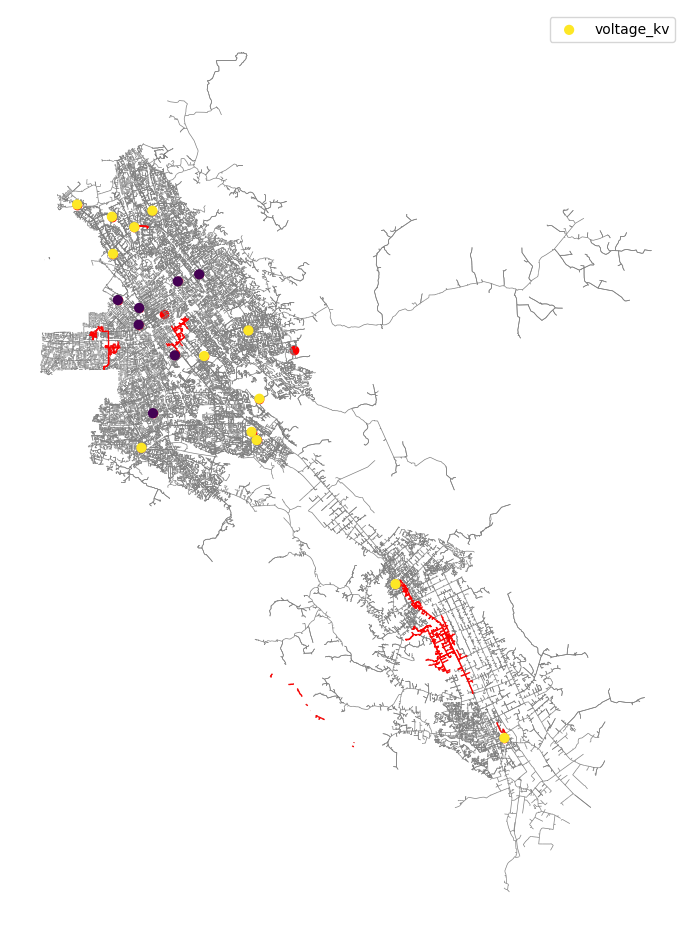

In [ ]:
#plot missing feeders w/ substations
fig, ax = plt.subplots(figsize=(12, 12))
gdf_substations.plot(ax=ax, color = 'red') #sub without voltage
gdf_lines.plot(ax=ax, color='gray', linewidth=0.5)
gdf_lines[gdf_lines['voltage_kv_clean'].isna()].plot(ax=ax, color='red', linewidth=1)
gdf_substations[gdf_substations['voltage_kv'].notna()].plot('voltage_kv', ax=ax, markersize=40, zorder=5, label='voltage_kv')
ax.set_axis_off()
ax.legend()
plt.show()

In [75]:
#list the substations that 
miss = gdf_lines[gdf_lines["voltage_kv_clean"].isna()].copy()
miss["sub_id"] = miss["FeederId"].astype(str).str[:5]
print(miss["sub_id"].value_counts().head(10))          

sub_id
08324    1553
08292     500
08370     427
08389      36
08319      35
08318      28
08343       1
Name: count, dtype: int64


In [77]:
#create new column with substation ID (first 5 of feederID)
gdf_lines['SubstationID'] = gdf_lines['FeederId'].astype(str).str[:5]

In [92]:
#create df with missing voltage values
miss = gdf_lines[gdf_lines['voltage_kv_clean'].isna()].copy()
#list substation IDs of the data missing voltage
print(miss["SubstationID"].value_counts().head(10))    

SubstationID
08324    1553
08292     500
08370     427
08389      36
08319      35
08318      28
08343       1
Name: count, dtype: int64


In [94]:
gdf_substations

,voltage_kv,NUMBANKS,REDACTED,UNGROUNDEDBANKS,Existing_DG,Queued_DG,OBJECTID,SubstationName,SubstationID,Division,Total_DG,Publish,Last_Update_On_Map,geometry
0,21.0,2.0,NO,None,0,0,10,RIVER OAKS,08234,San Jose,0,1,1793363013000,POINT (594949.555 4141038.926)
1,12.0,2.0,NO,None,8327,9125,26,STONE,08370,San Jose,17452,1,1793363013000,POINT (600304.133 4129231.08)
2,21.0,4.0,NO,None,2069,2915,30,EDENVALE,08295,San Jose,4984,1,1793363013000,POINT (606841.382 4122716.441)
3,12.0,3.0,NO,None,5988,6272,31,MC KEE,08353,San Jose,12260,1,1793363013000,POINT (602381.955 4136135.223)
4,21.0,3.0,NO,None,4950,4958,35,MONTAGUE,08389,San Jose,9908,1,1793363013000,POINT (596858.474 4140149.555)
5,12.0,4.0,NO,None,2169,3120,38,SAN JOSE A,08225,San Jose,5289,1,1793363013000,POINT (597228.346 4131842.863)
6,NaN,NaN,NaN,None,1000,1000,52,MARKHAM,08373,San Jose,2000,1,1793363013000,POINT (599353.082 4132761.37)
7,21.0,2.0,NO,None,4707,4860,59,EVERGREEN,08201,San Jose,9567,1,1793363013000,POINT (602804.954 4129174.652)
8,21.0,4.0,NO,None,0,1177,82,TRIMBLE,08380,San Jose,1177,1,1793363013000,POINT (595041.623 4137883.133)
9,21.0,3.0,NO,None,12338,16053,83,LLAGAS,08318,San Jose,28391,1,1793363013000,POINT (628384.772 4096643.682)


In [101]:
known = gdf_lines.dropna(subset=["voltage_kv_clean"]).copy()

In [106]:
check = known.merge(gdf_substations[["SubstationID", "voltage_kv"]],
                  left_on="SubstationID", right_on="SubstationID", how="left", suffixes=("_known", '_sub'))

issue where substation voltage is not matching feeders????

In [126]:
check.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 123336 entries, 0 to 123335
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   FeederId          123336 non-null  str     
 1   FeederName        94622 non-null   str     
 2   CSV_LineSection   63064 non-null   str     
 3   voltage_kv_known  94622 non-null   float64 
 4   phase_cnt         123285 non-null  float64 
 5   globalid          123336 non-null  str     
 6   Division          123336 non-null  str     
 7   geometry          123336 non-null  geometry
 8   source            123336 non-null  str     
 9   voltage_kv_clean  123336 non-null  float64 
 10  voltage_src       123336 non-null  str     
 11  SubstationID      123336 non-null  str     
 12  voltage_kv_sub    115019 non-null  float64 
dtypes: float64(4), geometry(1), str(8)
memory usage: 22.4 MB


In [110]:
print((check["voltage_kv_clean"].round(1) == check["voltage_kv_sub"].round(1)).mean())

0.7780291236946228


In [116]:
gdf_lines["SubstationID"] = gdf_lines["FeederId"].astype(str).str[:5]

known = gdf_lines.dropna(subset=["voltage_kv_clean"])
per_sub = known.groupby("SubstationID").voltage_kv_clean.agg(["nunique", "first"])
print((per_sub["nunique"] > 1).sum(), "substations with more than one voltage")

sub_volt = per_sub[per_sub["nunique"] == 1]["first"]      # only substations with a single voltage

5 substations with more than one voltage


In [117]:
gdf_lines_test = gdf_lines.copy()
fill = gdf_lines_test["voltage_kv_clean"].isna() & gdf_lines_test["SubstationID"].isin(sub_volt.index)
gdf_lines_test.loc[fill, "voltage_kv_clean"] = gdf_lines_test.loc[fill, "SubstationID"].map(sub_volt)
gdf_lines_test.loc[fill, "voltage_src"] = "substation"

In [118]:
gdf_lines_test.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 125916 entries, 0 to 125915
Data columns (total 13 columns):
 #   Column            Non-Null Count   Dtype   
---  ------            --------------   -----   
 0   FeederId          125916 non-null  str     
 1   FeederName        96851 non-null   str     
 2   CSV_LineSection   65293 non-null   str     
 3   voltage_kv        94622 non-null   float64 
 4   phase_cnt         125865 non-null  float64 
 5   globalid          125916 non-null  str     
 6   Division          125916 non-null  str     
 7   geometry          125916 non-null  geometry
 8   source            125916 non-null  str     
 9   voltage_kv_clean  125880 non-null  float64 
 10  voltage_src       125880 non-null  str     
 11  SubstationID      125916 non-null  str     
 12  sub_id            125916 non-null  str     
dtypes: float64(3), geometry(1), str(9)
memory usage: 23.5 MB


In [119]:
125880/125916

0.9997140951110264

In [120]:
gdf_lines_test['voltage_src'].value_counts()

voltage_src
data          94622
feeder        28714
substation     2544
Name: count, dtype: int64

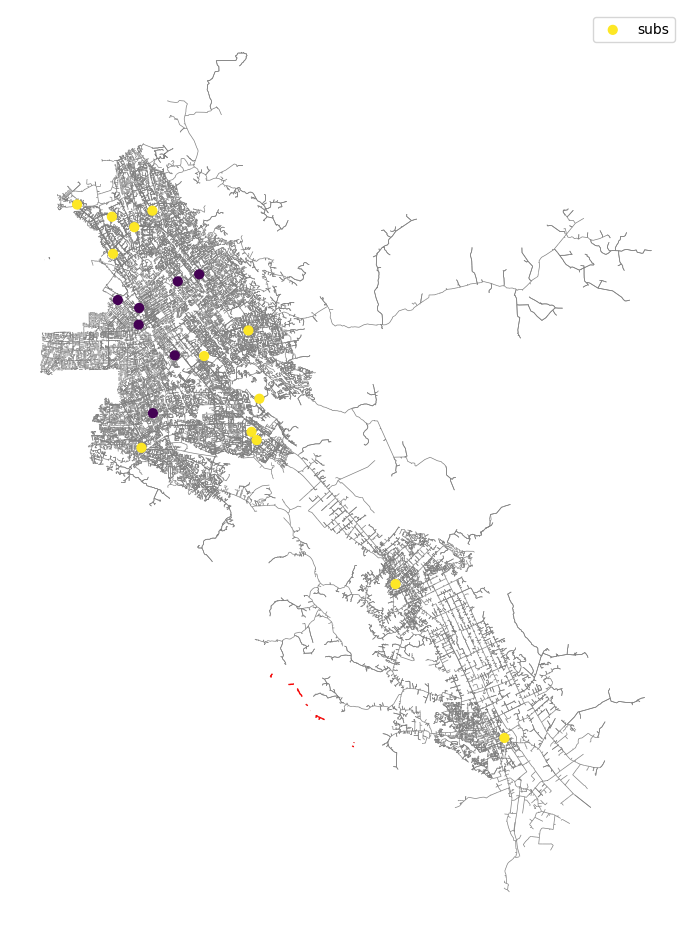

In [125]:
fig, ax = plt.subplots(figsize=(12, 12))
gdf_lines.plot(ax=ax, color='gray', linewidth=0.5)
gdf_lines_test[gdf_lines_test['voltage_kv_clean'].isna()].plot(ax=ax, color='red', linewidth=1)
gdf_substations[gdf_substations['voltage_kv'].notna()].plot('voltage_kv', ax=ax, markersize=40, zorder=5, label='subs')
ax.set_axis_off()
ax.legend()
plt.show()

### Export final cleaned data

In [ ]:
#export cleaned grid data to geopackage
gdf_lines.to_file(processed_data_fldr/"San_Jose_Cleaned_Voltage_Lines.gpkg",
                  driver="GPKG",
                  layer='lines')

In [128]:
gdf_system = gpd.read_file("C:/Users/sjh104/Downloads/DRPComplianceRelProd_4051649565345418525 (1).geojson")

In [132]:
gdf_lines['FeederId'].value_counts().count()

np.int64(192)

In [129]:
gdf_system.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 20 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   OBJECTID                150 non-null    int32   
 1   Substation              150 non-null    str     
 2   FeederID                150 non-null    str     
 3   Feeder_Name             150 non-null    str     
 4   Nominal_Voltage         150 non-null    float64 
 5   Load_Profile_Redaction  150 non-null    str     
 6   ResCust                 149 non-null    float64 
 7   ComCust                 149 non-null    float64 
 8   IndCust                 149 non-null    float64 
 9   AgrCust                 149 non-null    float64 
 10  OthCust                 149 non-null    float64 
 11  Existing_DG             150 non-null    int32   
 12  Queued_DG               150 non-null    int32   
 13  Total_DG                150 non-null    int32   
 14  Division          